# 01 - Data audit

Before any analysis: what exactly is in the files, how it was recorded, and what can go wrong
when reading it. Everything found here feeds later notebooks, and the data-quality findings
become requirements for the digital twin (notebook 06).

**Two data sources**

| Source | Used in | Rig | Logging |
|---|---|---|---|
| 47 recordings dated 30 May 2014: 6 healthy + 41 faulty | notebooks 02-04, 06-08 | UAV fuel-system demonstrator | NI DAQ, 1 kHz, 60 s per file |
| 22 pump tests: 16 "initial" (2021-07-28) and 6 "final" (2023-02-02) | notebooks 05, 07 | later PLC-based version of the testbed | PLC, 200 ms |

Raw files are read in place from the data folder; nothing is copied into the repository.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from fueltwin import config, features, plotting as pl, pump, rig

pl.use_style()
pd.set_option("display.precision", 4)
pd.set_option("display.width", 160)

## 1. The rig and where each fault is injected

Faults are *emulated*: a direct proportional valve (DPV) in series or in parallel with a component
changes the hydraulics the way the real failure would (rig documentation). The flow meter
sits at the **end** of the line, so it measures what reaches the sump, not what the pump produces.
This one detail decides which faults can be told apart (notebook 03).

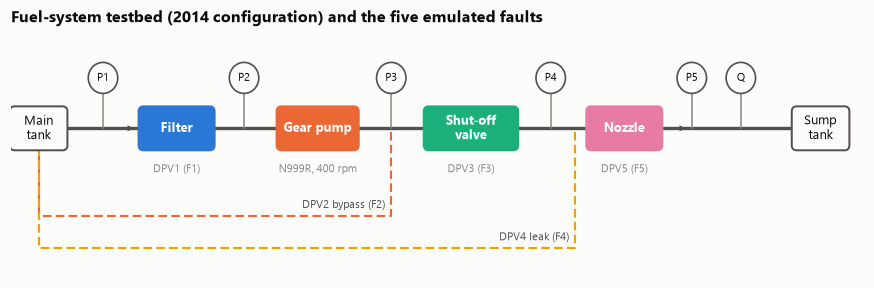

In [2]:
fig, ax = plt.subplots(figsize=(10, 2.9))
pl.schematic(ax, {"filter": pl.CONDITION_COLORS["F1"], "pump": pl.CONDITION_COLORS["F2"],
                  "bypass": pl.CONDITION_COLORS["F2"], "valve": pl.CONDITION_COLORS["F3"],
                  "leak": pl.CONDITION_COLORS["F4"], "nozzle": pl.CONDITION_COLORS["F5"]})
ax.set_title("Fuel-system testbed (2014 configuration) and the five emulated faults")
pl.save(fig, "01_rig_schematic")
plt.show()

In [3]:
pd.DataFrame([{"code": f.code, "fault": f.name, "component": f.component, "valve": f.valve.upper(),
               "healthy opening %": f.healthy_opening,
               "fault direction": "closing" if f.healthy_opening == 100 else "opening"}
              for f in config.FAULTS.values()])

,code,fault,component,valve,healthy opening %,fault direction
0,F1,Clogged filter,Suction filter,DPV1,100.0,closing
1,F2,Degraded pump,External gear pump,DPV2,0.0,opening
2,F3,Stuck valve,Shut-off valve (mid-range),DPV3,100.0,closing
3,F4,Leaking pipe,Pipe downstream of the shut-off valve,DPV4,0.0,opening
4,F5,Clogged injector,Injector / nozzle,DPV5,100.0,closing


## 2. File catalogue

Severity is defined here as **valve travel away from the healthy position** (%), read from the
valve column inside each file rather than from folder names. It is a control setting, not a physical
severity: how much a valve restricts flow is strongly non-linear in its travel.

In [4]:
cat = rig.catalogue()
cat.to_csv(config.TABLE_DIR / "01_rig_catalogue.csv", index=False)
summary = cat.groupby("condition", sort=False).agg(
    recordings=("file", "size"),
    severities=("severity", lambda s: ", ".join(f"{v:g}" for v in sorted(s))),
    first=("start", "min"), last=("start", "max"))
summary

,recordings,severities,first,last
condition,,,,
HC,6,"0, 0, 0, 0, 0, 0",2014-05-30 09:58:05,2014-05-30 10:03:05
F1,8,"10, 20, 30, 40, 50, 60, 70, 80",2014-05-30 10:04:40,2014-05-30 10:56:37
F2,9,"20, 30, 40, 50, 60, 70, 80, 90, 100",2014-05-30 11:05:43,2014-05-30 14:22:06
F3,8,"10, 20, 30, 40, 50, 60, 70, 80",2014-05-30 14:30:30,2014-05-30 14:56:17
F4,8,"20, 30, 40, 50, 60, 70, 80, 90",2014-05-30 15:02:59,2014-05-30 15:32:41
F5,8,"10, 20, 30, 40, 50, 60, 70, 80",2014-05-30 15:43:00,2014-05-30 16:11:08


In [5]:
checks = {
    "recordings": len(cat),
    "samples per file (all 60 000)": bool((cat["n_samples"] == 60000).all()),
    "valve settings constant within every file": True,  # catalogue() raises otherwise
}
data, _ = rig.load_all()
dt = np.diff(data.loc[data["run_id"] == "HC-1", "t"].to_numpy("float64"))
checks["sampling interval (ms)"] = f"{1000 * dt.mean():.3f} +/- {1000 * dt.std():.3f}"
checks["missing values"] = int(data.isna().sum().sum())
checks["pump speed, all files (rpm)"] = f"{data['rpm'].mean():.1f} (min {data['rpm'].min():.1f}, max {data['rpm'].max():.1f})"
pd.Series(checks, name="value").to_frame()

,value
recordings,47
samples per file (all 60 000),True
valve settings constant within every file,True
sampling interval (ms),1.000 +/- 0.001
missing values,0
"pump speed, all files (rpm)","400.0 (min 397.6, max 405.0)"


## 3. When were the recordings made? A built-in confound

The healthy baseline was recorded in the first six minutes of the day; every fault type was then
recorded as one block, in a fixed order, through to 16:11 (with a 2.5 h break inside the pump-fault
sweep). Anything that drifts slowly through the day (water temperature, tank level, atmospheric
pressure) is therefore tied to the fault label. Notebook 04 shows that a classifier given **only the
clock time** can name the fault almost perfectly, which is the clearest warning sign in this dataset.

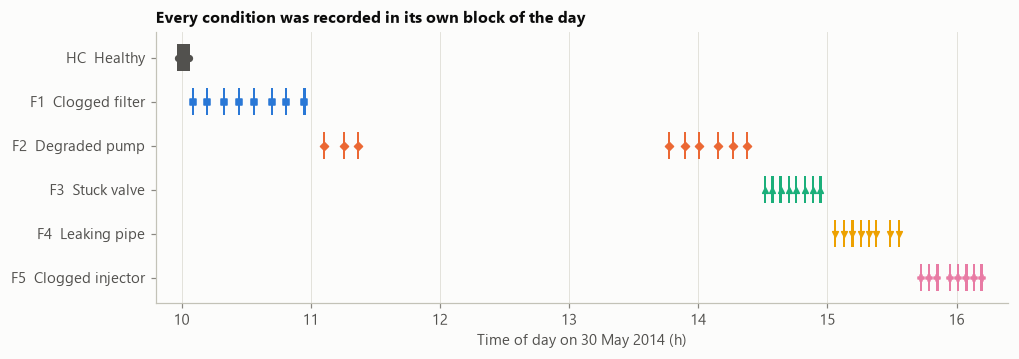

In [6]:
fig, ax = plt.subplots(figsize=(10, 3.2))
for i, c in enumerate(config.CONDITIONS):
    sub = cat[cat["condition"] == c]
    start = sub["start"].dt.hour + sub["start"].dt.minute / 60 + sub["start"].dt.second / 3600
    ax.barh(np.full(len(sub), i), np.full(len(sub), 1 / 60), left=start, height=0.6,
            color=pl.CONDITION_COLORS[c], edgecolor=pl.SURFACE, linewidth=0)
    ax.scatter(start + 0.5 / 60, np.full(len(sub), i), s=14, color=pl.CONDITION_COLORS[c],
               marker=pl.CONDITION_MARKERS[c], zorder=3)
ax.set_yticks(range(len(config.CONDITIONS)),
              [f"{c}  {config.CONDITION_NAMES[c]}" for c in config.CONDITIONS])
ax.invert_yaxis()
ax.set_xlabel("Time of day on 30 May 2014 (h)")
ax.set_xlim(9.8, 16.4)
ax.set_title("Every condition was recorded in its own block of the day")
ax.grid(axis="y", visible=False)
pl.save(fig, "01_recording_timeline")
plt.show()

## 4. Channels, units and reference pressures

From `File format.pdf`: P1 and P2 are **absolute**, P3-P5 are **gauge** (relative to atmosphere).
Atmospheric pressure was not logged, so P3-P5 are converted to absolute with the standard atmosphere
(1.01325 bar). Any quantity that mixes the two groups (most importantly the pump pressure rise
P3 - P2) inherits the day's weather error, roughly +/- 0.02 bar. Column 6 is documented as
"ignore"; it is kept only to show below that it is not empty.

In [7]:
channel_map = pd.DataFrame({
    "column": range(1, 15),
    "name in file": ["X_Value", "Pre-Filter Pressure Transducer", "Post Filter Pressure Transducer",
                     "Pre Valve Pressure Transducer", "Post Valve Pressure Transducer", "Main Tank Flow Meter",
                     "Sump Tank Flow Meter", "End Pressure", "Untitled", "Untitled 1", "Untitled 2",
                     "Untitled 3", "Untitled 4", "Untitled 5"],
    "used as": rig.RAW_COLUMNS,
    "meaning (File format.pdf)": ["time (s)", "P1 before filter, bar abs", "P2 after filter, bar abs",
                                  "P3 after pump, bar gauge", "P4 after shut-off valve, bar gauge",
                                  "ignore", "Q main-line flow, L/min", "P5 after nozzle, bar gauge",
                                  "pump speed, rpm", "DPV1 opening %", "DPV2 opening %", "DPV3 opening %",
                                  "DPV4 opening %", "DPV5 opening %"],
})
channel_map

,column,name in file,used as,meaning (File format.pdf)
0,1,X_Value,t,time (s)
1,2,Pre-Filter Pressure Transducer,P1,"P1 before filter, bar abs"
2,3,Post Filter Pressure Transducer,P2,"P2 after filter, bar abs"
3,4,Pre Valve Pressure Transducer,P3g,"P3 after pump, bar gauge"
4,5,Post Valve Pressure Transducer,P4g,"P4 after shut-off valve, bar gauge"
5,6,Main Tank Flow Meter,ch6_ignored,ignore
6,7,Sump Tank Flow Meter,Q,"Q main-line flow, L/min"
7,8,End Pressure,P5g,"P5 after nozzle, bar gauge"
8,9,Untitled,rpm,"pump speed, rpm"
9,10,Untitled 1,dpv1,DPV1 opening %


Note that the file's own labels for columns 6 and 7 ("Main Tank Flow Meter", "Sump Tank Flow Meter")
do not match the documented meaning; the documentation is followed. The labels are a reminder that
channel names in a logger configuration are not a data contract.

## 5. Sensor resolution and noise floor

In [8]:
hc1 = data[data["run_id"] == "HC-1"]
res = {}
for c in ["P1", "P2", "P3g", "P4g", "P5g", "Q", "rpm"]:
    v = np.unique(hc1[c].to_numpy("float64"))
    steps = np.diff(v)
    res[c] = {"distinct values in 60 s": len(v), "smallest step": steps[steps > 1e-7].min(),
              "raw sd (1 kHz)": hc1[c].std()}
pd.DataFrame(res).T

,distinct values in 60 s,smallest step,raw sd (1 kHz)
P1,258.0,0.0003,0.0135
P2,311.0,0.0003,0.0153
P3g,210.0,0.0001,0.0045
P4g,162.0,0.0001,0.0028
P5g,303.0,0.0001,0.0069
Q,262.0,0.0001,0.0028
rpm,118.0,0.0001,0.5621


The quantisation steps (0.3 mbar for P1/P2, 0.13 mbar for P3-P5, 0.00013 L/min for Q) are far below
the noise, so resolution is not a limitation. The 1 kHz noise (around 10 mbar on P1/P2) is dominated
by gear-pump ripple and electrical noise, studied in notebook 02.

## 6. P5 hits the bottom of its range

When the flow drops far enough (degraded pump >= 60 %, leak >= 70 %), the pressure after the nozzle
falls to atmospheric and the sensor reads exactly 0.000 bar for a large share of samples. Those
readings are censored: the true value can be at or below zero but the sensor cannot say. Anything
computed from P5 in those runs (the nozzle pressure drop in particular) is unreliable, and the twin
must flag it rather than trust it.

In [9]:
floor = (data.assign(at_floor=data["P5g"] <= 1e-6)
         .groupby("run_id", observed=True)["at_floor"].mean().reindex(cat["run_id"]))
low = data.groupby("run_id", observed=True)["P5g"].apply(lambda s: (s <= 0.001).mean()).reindex(cat["run_id"])
p5 = pd.DataFrame({"condition": cat["condition"].to_numpy(), "severity": cat["severity"].to_numpy(),
                   "share exactly 0": floor.to_numpy(), "share <= 1 mbar": low.to_numpy()}, index=cat["run_id"])
p5[p5["share <= 1 mbar"] > 0.01]

,condition,severity,share exactly 0,share <= 1 mbar
run_id,,,,
F2-060,F2,60.0,0.2908,0.9916
F2-070,F2,70.0,0.3073,0.9916
F2-080,F2,80.0,0.2989,0.9917
F2-090,F2,90.0,0.3134,0.9915
F2-100,F2,100.0,0.2935,0.9913
F4-070,F4,70.0,0.0068,0.2842
F4-080,F4,80.0,0.2397,0.9892
F4-090,F4,90.0,0.2499,0.9889


## 7. The "ignore" channel is not empty

Column 6 responds strongly to faults (it falls with the pump and leak faults and rises sharply with
the clogged injector), so it is a live measurement of something. Without documentation of what it is
it cannot be interpreted, so it is excluded from every model, as the rig documentation instructs.

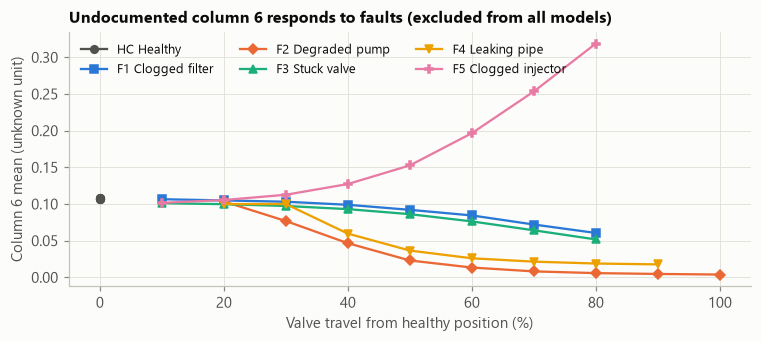

In [10]:
ch6 = data.groupby("run_id", observed=True)["ch6_ignored"].mean().reindex(cat["run_id"])
fig, ax = plt.subplots(figsize=(8, 3))
for c in config.CONDITIONS:
    m = cat["condition"] == c
    ax.plot(cat.loc[m, "severity"], ch6[m.to_numpy()], marker=pl.CONDITION_MARKERS[c], ms=5,
            color=pl.CONDITION_COLORS[c], label=f"{c} {config.CONDITION_NAMES[c]}", lw=1.5)
ax.set_xlabel("Valve travel from healthy position (%)")
ax.set_ylabel("Column 6 mean (unknown unit)")
ax.set_title("Undocumented column 6 responds to faults (excluded from all models)")
ax.legend(ncol=3, loc="upper left")
pl.save(fig, "01_ignored_channel")
plt.show()

## 8. Pump test campaigns

Facts checked against the Pump Datasets Specification:
* the time column is all zeros; time is rebuilt from the 200 ms PLC period;
* the flow column is labelled `F1 (bar)` but holds L/min;
* both main-line valves (DPV3 and DPV4 commands) always move together;
* the valve command maps 20 000 = fully open to 4 000 = fully closed.

In [11]:
pt = pump.load_all()
const = {c: pt[c].unique().tolist() for c in ["temp_C", "visc_Pa_s", "rho", "patm"]}
print("Columns that never change in any pump file:", const)
print("Time column in the raw files is all zeros:", bool((pump.read_lvm(
    next((config.PUMP_DIR / pump.CAMPAIGN_DIRS["final"]).glob("*.lvm"))).data["X_Value"] == 0).all()))
tests = pump.test_summary(pt)
tests.to_csv(config.TABLE_DIR / "01_pump_tests.csv", index=False)
tests

Columns that never change in any pump file: {'temp_C': [24.0], 'visc_Pa_s': [0.000912], 'rho': [997.54048], 'patm': [1.0]}
Time column in the raw files is all zeros: True


,test,campaign,nominal_rpm,rpm_measured,n,duration_s,valve_start_pct,valve_end_pct,valves_match,dP_start,dP_max,Q_start,Q_end
0,final-700,final,700,700.0,860,171.8,100.0,24.9,True,1.1768,3.184,1.2278,0.8130
1,final-750,final,750,750.0,1047,209.2,100.0,34.9,True,1.3131,2.808,1.3018,1.0061
2,final-800,final,800,800.0,718,143.4,100.0,34.9,True,1.4732,2.949,1.3737,1.0946
3,final-850,final,850,850.0,741,148.0,100.0,34.9,True,1.6308,3.116,1.4499,1.1750
4,final-900,final,900,900.0,820,163.8,100.0,34.9,True,1.7999,3.261,1.5308,1.2401
5,final-950,final,950,950.0,740,147.8,100.0,34.9,True,1.9508,3.367,1.6007,1.2969
6,initial-400,initial,400,400.0,1200,239.8,100.0,9.9,True,0.4475,2.612,0.7002,0.1656
7,initial-450,initial,450,450.0,1200,239.8,100.0,9.9,True,0.5403,3.303,0.7844,0.1239
8,initial-500,initial,500,500.0,1200,239.8,100.0,9.9,True,0.6518,3.434,0.8718,0.2058
9,initial-550,initial,550,550.0,1200,239.8,100.0,9.9,True,0.7645,3.542,0.9562,0.2896


The temperature (24 C), viscosity, density and atmospheric pressure columns are constants written by
the logging software, not measurements. Fluid temperature was therefore **never measured** in either
rig, even though it governs the internal leakage of a gear pump. This gap returns in notebooks 03 and
06.

The pump-file name encodes the final valve opening (`PT_700rpm_25_` means the valves stopped at 25 %
open); the table confirms this from the logged commands.

## 9. Data-quality findings carried forward

| Finding | Consequence | Where it is used |
|---|---|---|
| Conditions recorded in time-ordered blocks; healthy only at 09:58-10:03 | label is confounded with time of day | 03 (drift), 04 (shortcut test), 06 |
| P3-P5 gauge, P1-P2 absolute, no atmospheric pressure logged | +/- 0.02 bar uncertainty on P3 - P2 | 02, 03, 06 (requirement: log P_atm) |
| P5 censored at 0 bar gauge at high fault severity | nozzle residual invalid in those windows | 03, 06 (quality indicator) |
| Column 6 live but undocumented | excluded | - |
| No fluid temperature in either rig | pump slip drift cannot be compensated | 03, 05, 06 (requirement) |
| Pump files: time all zeros, flow mislabelled, constant "model" columns | rebuilt / relabelled / ignored | 05 |